# Problem 4.7

Implement the two line search algorithms from Section 4.3, such that they work in $n$ dimensions ($x$ and $p$ can be vectors of any size).

a. As a first test for your code, reproduce the results from the examples in Section 4.3 and plot the function and iterations for both algorithms. For the line search that satisfies the strong Wolfe conditions, reduce the value of $\mu_2$ until you get an exact line search. How much accuracy can you achieve?

b. Test your code on another easy two-dimensional function, such as the bean function from Ex. 4.11, starting from different points and using different directions (but remember that you must always provide a valid descent direction; otherwise, the algorithm might not work!). Does it always find a suitable point? Exploration: Try different values of $\mu_2$ and $\rho$ to analyze their effect on the number of iterations.

c. Apply your line search algorithms to the two-dimensional Rosenbrock function and then the $n$-dimensional variant (see Section D.1.2). Again, try different points and search directions to see how robust the algorithm is, and try to tune $\mu_2$ and $\rho$.

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

## Approach

In [2]:
def f_ls(x):
    """Two-variable function of the line search examples (Ex. 4.8 / 4.9), section 4.3."""
    return (0.1 * x[0] ** 6 - 1.5 * x[0] ** 4 + 5 * x[0] ** 2
            + 0.1 * x[1] ** 4 + 3 * x[1] ** 2 - 9 * x[1] + 0.5 * x[0] * x[1])

# example setup from the book: start, direction, parameters
x0_ls = np.array([-1.25, 1.25])
p_ls = np.array([4.0, 0.75])
mu1, mu2, rho = 1e-4, 0.9, 0.7   # sigma = 2 for the bracketing; alpha_init = 1.2 (large) or 0.05 (small)

def grad_f_ls(x):
    """Gradient of the two-variable function of the line search examples (Ex. 4.8 / 4.9), section 4.3."""
    return np.array([0.6 * x[0] ** 5 - 6 * x[0] ** 3 + 10 * x[0] + 0.5 * x[1],
                     0.4 * x[1] ** 3 + 6 * x[1] - 9 + 0.5 * x[0]])

In [3]:
def bean(x):
    """Bean function (Ex. 4.11 in the book's numbering)."""
    return (1 - x[0]) ** 2 + (1 - x[1]) ** 2 + 0.5 * (2 * x[1] - x[0] ** 2) ** 2

def grad_bean(x):
    """Gradient of the bean function (Ex. 4.11 in the book's numbering)."""
    return np.array([-2 * (1 - x[0]) - 2 * x[0] * (2 * x[1] - x[0] ** 2),
                     -2 * (1 - x[1]) + 2 * (2 * x[1] - x[0] ** 2)])

In [4]:
def rosenbrock(x):
    """n-dimensional Rosenbrock (D.1.2); x* = (1, ..., 1), f* = 0."""
    x = np.asarray(x, dtype=float)
    return np.sum(100 * (x[1:] - x[:-1] ** 2) ** 2 + (1 - x[:-1]) ** 2)

def grad_rosenbrock(x):
    """Gradient of the n-dimensional Rosenbrock (D.1.2); x* = (1, ..., 1), f* = 0."""
    x = np.asarray(x, dtype=float)
    grad = np.zeros_like(x)
    grad[0] = -400 * x[0] * (x[1] - x[0] ** 2) - 2 * (1 - x[0])
    for i in range(1, len(x) - 1):
        grad[i] = 200 * (x[i] - x[i - 1] ** 2) - 400 * x[i] * (x[i + 1] - x[i] ** 2) - 2 * (1 - x[i])
    grad[-1] = 200 * (x[-1] - x[-2] ** 2)
    return grad

In [5]:
class Counted:
    """Wrap a function to count evaluations: g = Counted(f); g(x); g.n."""
    def __init__(self, fun):
        self.fun, self.n = fun, 0
    def __call__(self, *args, **kwargs):
        self.n += 1
        return self.fun(*args, **kwargs)

def contour(f, xlim, ylim, n=200, levels=40, ax=None):
    """Contour plot of a 2D function f(x) with x = [x1, x2]; returns the axes."""
    x1, x2 = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    z = np.vectorize(lambda a, b: f(np.array([a, b])))(x1, x2)
    if ax is None:
        _, ax = plt.subplots()
    ax.contour(x1, x2, z, levels=levels)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    return ax

def lineplot(f, x, p, alpha_max=1.0, n=200, ax=None):
    """Plot phi(alpha) = f(x + alpha * p) for alpha in [0, alpha_max].

    f: function of an n-dimensional vector, x: starting point, p: search direction
    (both arrays of the same size). Returns the axes.
    """
    x = np.asarray(x, dtype=float)
    p = np.asarray(p, dtype=float)
    alphas = np.linspace(0, alpha_max, n)
    phi = np.array([f(x + a * p) for a in alphas])
    if ax is None:
        _, ax = plt.subplots()
    ax.plot(alphas, phi)
    ax.plot(0, phi[0], "ro", label=r"$\alpha = 0$ (start)")
    ax.set_xlabel(r"step length $\alpha$")
    ax.set_ylabel(r"$\phi(\alpha) = f(x + \alpha p)$")
    ax.legend()
    return ax


In [6]:
# signatures only; fill in. x, p are arrays of any size; return the step length and whatever counts you need
def backtracking(f, grad, x, p, alpha_init=1.0, mu1=1e-4, rho=0.7):
    """Backtracking line search to satisfy the Armijo condition (sufficient decrease)."""
    
    alpha = alpha_init
    alpha_list = [alpha]
    while f(x + alpha * p) > f(x) + mu1 * alpha * grad(x + alpha * p).dot(p):
        #while the function is aboce the sufficient decrease line, backtrack
        alpha *= rho
        alpha_list.append(alpha)
    return alpha, alpha_list

In [7]:
def _interpolate(alpha_low, alpha_high, phi_low, phi_high, grad_phi_low, grad_phi_high):
    """Cubic interpolation to find the minimum of a function in an interval."""
    betha1 = grad_phi_low + grad_phi_high - 3 * (phi_low - phi_high) / (alpha_low - alpha_high)
    betha2 = np.sign(alpha_high - alpha_low) * np.sqrt(betha1 ** 2 - grad_phi_low * grad_phi_high)
    alpha_p = alpha_high - (alpha_high - alpha_low) * (grad_phi_high + betha2 - betha1) \
        / (grad_phi_high - grad_phi_low + 2 * betha2)
    return alpha_p

In [8]:
def _pinpoint(f, grad, x, p, alpha_low, alpha_high, mu1, mu2):
    """Returns the step length and the pinpointing history [(alpha_low, alpha_high, alpha_p), ...]."""
    phi_0 = f(x)                # function value at the current point
    grad_phi_0 = grad(x).dot(p) # directional derivative at the current point
    phi_low = f(x + alpha_low * p)                # function value at the lower bound
    grad_phi_low = grad(x + alpha_low * p).dot(p) # directional derivative
    phi_high = f(x + alpha_high * p)                # function value at the upper bound
    grad_phi_high = grad(x + alpha_high * p).dot(p) # directional derivative

    history = []  # one entry per pinpointing iteration: interval and trial step
    k = 0
    while True:
        alpha_p = _interpolate(alpha_low, alpha_high, phi_low, phi_high, grad_phi_low, grad_phi_high)
        history.append((alpha_low, alpha_high, alpha_p))  # interval used and trial step found in it
        phi_p = f(x + alpha_p * p)                # function value at the minimum in the inteval        
        grad_phi_p = grad(x + alpha_p * p).dot(p) # directional derivative
        
        if phi_p > phi_0 + mu1 * alpha_p * grad_phi_0 or phi_p > phi_low:
            # if the function value is above the sufficient decrease line or above the lower bound value, then update the upper bound
            alpha_high = alpha_p
            phi_high = phi_p
            grad_phi_high = grad_phi_p
        else:
            if abs(grad_phi_p) <= - mu2 * grad_phi_0:
                # if the directional derivative is low enough we have a good step length
                return alpha_p, history
            elif grad_phi_p * (alpha_high - alpha_low) >= 0:
                # if the directional derivative is positve then update the upper bound to the lower bound
                # positive here means the slope is dereasing towards the lower bound
                alpha_high = alpha_low
                phi_high = phi_low
                grad_phi_high = grad_phi_low
            alpha_low = alpha_p
            phi_low = phi_p
            grad_phi_low = grad_phi_p

        if k > 100:
            raise RuntimeError("Pinpointing failed to converge after 100 iterations.")
        k += 1

In [9]:
def bracketing_pinpointing(f, grad, x, p, alpha_init=1.0, mu1=1e-4, mu2=0.9, sigma=2.0):
    """Returns alpha_star and a history dict:
    {"bracketing": [(alpha_1, alpha_2), ...], "pinpointing": [(alpha_low, alpha_high, alpha_p), ...]}"""
    alpha_1 = 0             # lower bound on the step length
    alpha_2 = alpha_init    # upper bound on the step length (and initial guess)
    
    phi_0 = f(x)                # function value at the current point
    grad_phi_0 = grad(x).dot(p) # directional derivative at the current point
    phi_1 = phi_0               # function value at the lower bound
    grad_phi_1 = grad_phi_0     # directional derivative at the lower bound
    first = True

    bracket_history = []  # one entry per bracketing iteration: (alpha_1, alpha_2)

    while True: # infinte loop
        bracket_history.append((alpha_1, alpha_2))
        phi_2 = f(x + alpha_2 * p)                # calculate function value at upper bound
        grad_phi_2 = grad(x + alpha_2 * p).dot(p) # calculate directional derivative at upper bound

        if phi_2 > phi_0 + mu1 * alpha_2 * grad_phi_0 or (not first and phi_2 > phi_1):
            # if the upper bound value is above the min decrease line or above the lower bound value, then pinpoint
            alpha_star, pin_history = _pinpoint(f, grad, x, p, alpha_1, alpha_2, mu1, mu2)
            return alpha_star, {"bracketing": bracket_history, "pinpointing": pin_history}
        if abs(grad_phi_2) <= -mu2 * grad_phi_0:
            # if the directional derivative is low enough we have a good step length
            return alpha_2, {"bracketing": bracket_history, "pinpointing": []}
        elif grad_phi_2 >= 0:
            # if the directional derrivative is positive (and the previous condition was met) then we pinpoint
            alpha_star, pin_history = _pinpoint(f, grad, x, p, alpha_2, alpha_1, mu1, mu2)
            return alpha_star, {"bracketing": bracket_history, "pinpointing": pin_history}
        else:
            # up date lower and upper bounds and continue searching
            alpha_1 = alpha_2
            phi_1 = phi_2
            grad_phi_1 = grad_phi_2
            alpha_2 *= sigma
        first = False

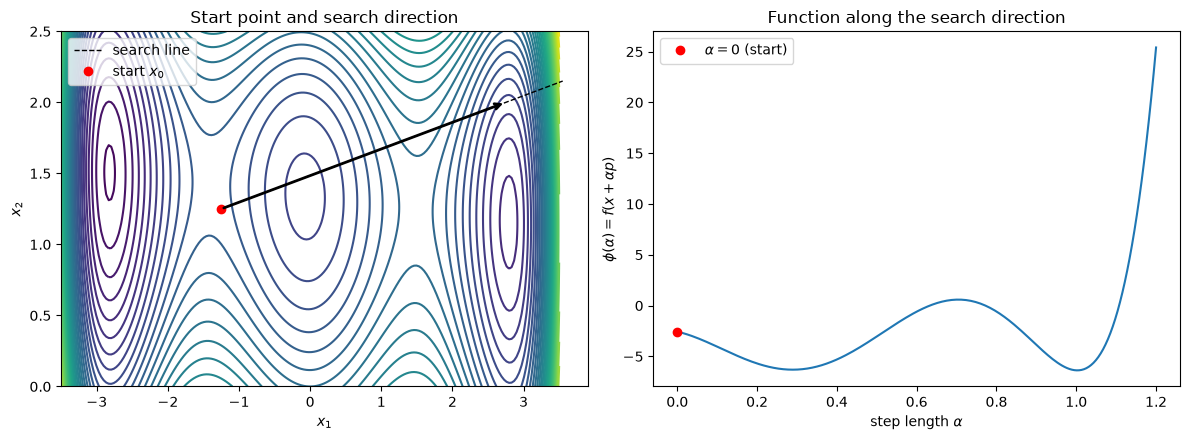

In [10]:
# example 4.8 (f_ls): search direction in the contour plot (left) and the slice along it (right)
alpha_max = 1.2
fig, (ax_contour, ax_line) = plt.subplots(1, 2, figsize=(12, 4.5))

# left: contours with start point, search direction (arrow) and search line
contour(f_ls, (-3.5, 3.5), (0, 2.5), ax=ax_contour)
end = x0_ls + alpha_max * p_ls
ax_contour.plot(*zip(x0_ls, end), "k--", lw=1, label="search line")
ax_contour.annotate("", xy=x0_ls + p_ls, xytext=x0_ls,
                    arrowprops=dict(arrowstyle="->", color="k", lw=2))
ax_contour.plot(*x0_ls, "ro", label="start $x_0$")
ax_contour.set_title("Start point and search direction")
ax_contour.legend(loc="upper left")

# right: f along the search direction
lineplot(f_ls, x0_ls, p_ls, alpha_max=alpha_max, ax=ax_line)
ax_line.set_title("Function along the search direction")

plt.tight_layout()
plt.show()


Backtracking step length: 0.4116
Backtracking step lengths: [1.2, 0.84, 0.588, 0.4116]
Function evaluations: 8, gradient evaluations: 4


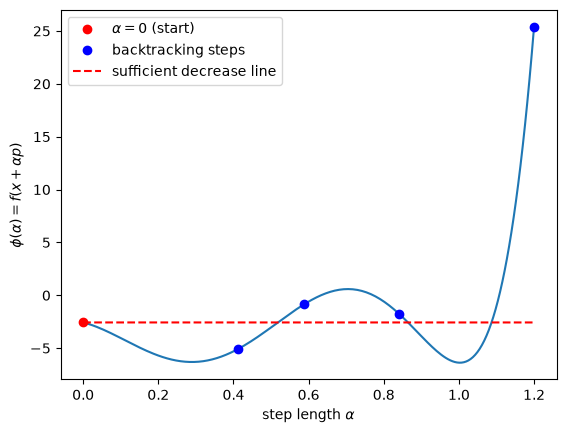

In [11]:
# start with solving example 4.8 (f_ls) with backtracking
x0 = np.array([-1.25, 1.25]) # starting point
p = np.array([4.0, 0.75]) # search direction

alpha_init=1.2
mu1=1e-4
rho=0.7

# new counters every time the cell runs, so the counts always start from zero
f_count = Counted(f_ls)
grad_count = Counted(grad_f_ls)

step,list = backtracking(f_count, grad_count, x0, p, alpha_init=alpha_init, mu1=mu1, rho=rho)
print(f"Backtracking step length: {step:.4f}")
print(f"Backtracking step lengths: {[round(a, 4) for a in list]}")
print(f"Function evaluations: {f_count.n}, gradient evaluations: {grad_count.n}")

# plot the function along the search direction with all the backtracking step lengths
# (plain f_ls / grad_f_ls from here on, so the plotting calls are not counted)
alpha_max = 1.2
ax = lineplot(f_ls, x0, p, alpha_max=alpha_max)
alpha_list = np.array(list)
phi_list = [f_ls(x0 + a * p) for a in alpha_list]   # f_ls takes one point at a time
ax.plot(alpha_list, phi_list, "bo", label="backtracking steps")

# sufficient decrease line: phi(0) + mu1 * alpha * phi'(0)
phi_0 = f_ls(x0)
grad_phi_0 = grad_f_ls(x0).dot(p)    # directional derivative at alpha = 0
alphas = np.array([0, alpha_max])
ax.plot(alphas, phi_0 + mu1 * alphas * grad_phi_0, "r--", label="sufficient decrease line")
ax.legend()

Bracketing and pinpointing step length: 0.2551
Bracketing intervals (alpha_1, alpha_2): [[0.0, 1.2]]
Pinpointing (alpha_low, alpha_high, alpha_p): [[0.0, 1.2, 0.7469], [0.0, 0.7469, 0.0947], [0.0947, 0.7469, 0.1981], [0.1981, 0.7469, 0.2551]]
Function evaluations: 9, gradient evaluations: 9


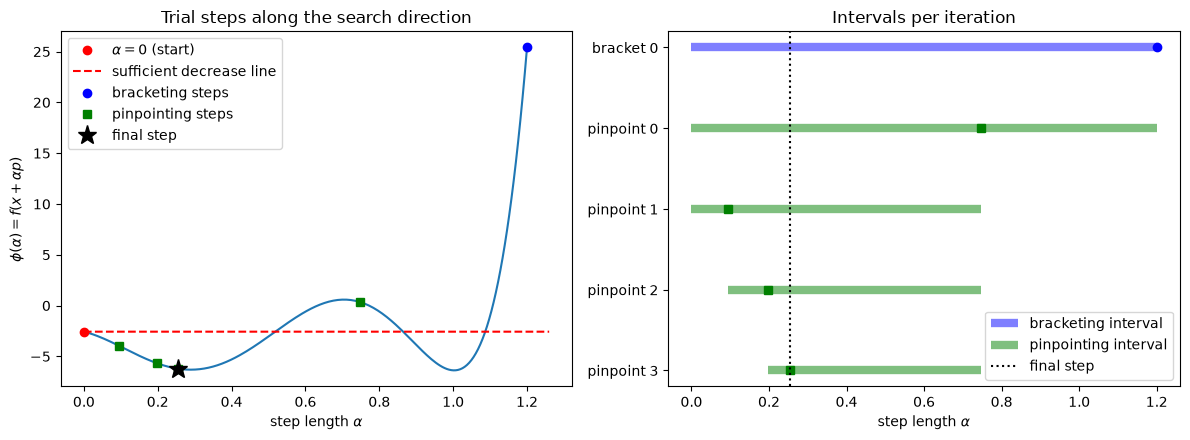

In [12]:
# solve example 4.8 (f_ls) with bracketing and pinpointing
x0 = np.array([-1.25, 1.25]) # starting point
p = np.array([4.0, 0.75]) # search direction

alpha_init = 1.2
mu1, mu2, sigma = 1e-4, 0.9, 2.0

# new counters every time the cell runs, so the counts always start from zero
f_count = Counted(f_ls)
grad_count = Counted(grad_f_ls)

# the wrapped functions (not f_ls / grad_f_ls) must be passed to the line search to be counted
step, history = bracketing_pinpointing(f_count, grad_count, x0, p, alpha_init=alpha_init, mu1=mu1, mu2=mu2, sigma=sigma)
print(f"Bracketing and pinpointing step length: {step:.4f}")

bracket = np.array(history["bracketing"]).reshape(-1, 2)    # columns: alpha_1, alpha_2
pin = np.array(history["pinpointing"]).reshape(-1, 3)       # columns: alpha_low, alpha_high, alpha_p
print(f"Bracketing intervals (alpha_1, alpha_2): {np.round(bracket, 4).tolist()}")
print(f"Pinpointing (alpha_low, alpha_high, alpha_p): {np.round(pin, 4).tolist()}")
print(f"Function evaluations: {f_count.n}, gradient evaluations: {grad_count.n}")

phi = lambda a: f_ls(x0 + a * p)
alpha_max = 1.05 * max(bracket.max(), pin.max() if len(pin) else 0)

fig, (ax_phi, ax_int) = plt.subplots(1, 2, figsize=(12, 4.5))

# left: phi(alpha) with the sufficient decrease line and all trial steps
lineplot(f_ls, x0, p, alpha_max=alpha_init, ax=ax_phi)
grad_phi_0 = grad_f_ls(x0).dot(p)
alphas = np.array([0, alpha_max])
ax_phi.plot(alphas, phi(0) + mu1 * alphas * grad_phi_0, "r--", label="sufficient decrease line")
ax_phi.plot(bracket[:, 1], [phi(a) for a in bracket[:, 1]], "bo", label="bracketing steps")
if len(pin):
    ax_phi.plot(pin[:, 2], [phi(a) for a in pin[:, 2]], "gs", label="pinpointing steps")
ax_phi.plot(step, phi(step), "k*", ms=14, label="final step")
ax_phi.set_title("Trial steps along the search direction")
ax_phi.legend()

# right: the interval of every iteration (bracketing, then pinpointing), with the trial step
row = 0
for a1, a2 in bracket:
    ax_int.hlines(row, min(a1, a2), max(a1, a2), colors="b", lw=6, alpha=0.5,
                  label="bracketing interval" if row == 0 else None)
    ax_int.plot(a2, row, "bo")
    row += 1
for j, (a_low, a_high, a_p) in enumerate(pin):
    ax_int.hlines(row, min(a_low, a_high), max(a_low, a_high), colors="g", lw=6, alpha=0.5,
                  label="pinpointing interval" if j == 0 else None)
    ax_int.plot(a_p, row, "gs")
    row += 1
ax_int.axvline(step, color="k", ls=":", label="final step")
ax_int.invert_yaxis()
ax_int.set_yticks(range(row))
ax_int.set_yticklabels([f"bracket {k}" for k in range(len(bracket))]
                       + [f"pinpoint {j}" for j in range(len(pin))])
ax_int.set_xlabel(r"step length $\alpha$")
ax_int.set_title("Intervals per iteration")
ax_int.legend()

plt.tight_layout()
plt.show()

Bracketing and pinpointing step length: 0.4936
Bracketing intervals (alpha_1, alpha_2): [[0.0, 1.2]]
Pinpointing (alpha_low, alpha_high, alpha_p): [[0.0, 1.2, 0.4936]]
Function evaluations: 6, gradient evaluations: 6


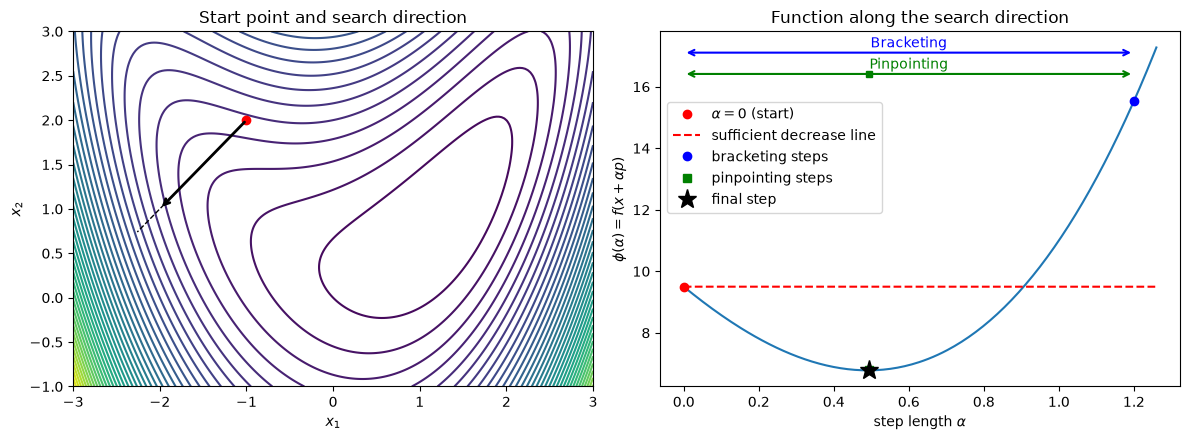

In [13]:
# solve example 4.11 (bean) with bracketing and pinpointing
x0 = np.array([-1, 2]) # starting point
p = np.array([-1, -1]) # search direction

alpha_init = 1.2
mu1, mu2, sigma = 1e-4, 0.9, 2.0

# new counters every time the cell runs, so the counts always start from zero
f_count = Counted(bean)
grad_count = Counted(grad_bean)

step, history = bracketing_pinpointing(f_count, grad_count, x0, p, alpha_init=alpha_init, mu1=mu1, mu2=mu2, sigma=sigma)
print(f"Bracketing and pinpointing step length: {step:.4f}")

bracket = np.array(history["bracketing"]).reshape(-1, 2)    # columns: alpha_1, alpha_2
pin = np.array(history["pinpointing"]).reshape(-1, 3)       # columns: alpha_low, alpha_high, alpha_p
print(f"Bracketing intervals (alpha_1, alpha_2): {np.round(bracket, 4).tolist()}")
print(f"Pinpointing (alpha_low, alpha_high, alpha_p): {np.round(pin, 4).tolist()}")
print(f"Function evaluations: {f_count.n}, gradient evaluations: {grad_count.n}")

phi = lambda a: bean(x0 + a * p)
alpha_max = 1.05 * max(bracket.max(), pin.max() if len(pin) else 0)

# plot stuff
fig, (ax_contour, ax_line) = plt.subplots(1, 2, figsize=(12, 4.5))

# contour plot
ax_contour = contour(bean, (-3, 3), (-1, 3), ax=ax_contour)
end = x0 + alpha_max * p
ax_contour.plot(*zip(x0, end), "k--", lw=1, label="search line")
ax_contour.annotate("", xy=x0 + p, xytext=x0,
                    arrowprops=dict(arrowstyle="->", color="k", lw=2))
ax_contour.plot(*x0, "ro", label="start $x_0$")
ax_contour.set_title("Start point and search direction")

# line plot: phi(alpha), sufficient decrease line, trial steps and the interval history
lineplot(bean, x0, p, alpha_max=alpha_max, ax=ax_line)
grad_phi_0 = grad_bean(x0).dot(p)
alphas = np.array([0, alpha_max])
ax_line.plot(alphas, phi(0) + mu1 * alphas * grad_phi_0, "r--", label="sufficient decrease line")
ax_line.plot(bracket[:, 1], [phi(a) for a in bracket[:, 1]], "bo", label="bracketing steps")
if len(pin):
    ax_line.plot(pin[:, 2], [phi(a) for a in pin[:, 2]], "gs", label="pinpointing steps")
ax_line.plot(step, phi(step), "k*", ms=14, label="final step")

# interval arrows stacked from the top: x in data coordinates, y as a fraction of the axes height
trans = ax_line.get_xaxis_transform()
y, dy = 0.94, 0.06
for k, (a1, a2) in enumerate(bracket):
    ax_line.annotate("", xy=(a2, y), xytext=(a1, y), xycoords=trans,
                     arrowprops=dict(arrowstyle="<->", color="b", lw=1.5))
    if k == 0:
        ax_line.text((a1 + a2) / 2, y + 0.015, "Bracketing", transform=trans, ha="center", color="b")
    y -= dy
for j, (a_low, a_high, a_p) in enumerate(pin):
    ax_line.annotate("", xy=(a_high, y), xytext=(a_low, y), xycoords=trans,
                     arrowprops=dict(arrowstyle="<->", color="g", lw=1.5))
    ax_line.plot(a_p, y, "gs", ms=4, transform=trans)       # trial step inside the interval
    if j == 0:
        ax_line.text((a_low + a_high) / 2, y + 0.015, "Pinpointing", transform=trans, ha="center", color="g")
    y -= dy
ax_line.set_title("Function along the search direction")
ax_line.legend(loc="upper left", bbox_to_anchor=(0.0, y))    # below the interval arrows

plt.tight_layout()
plt.show()

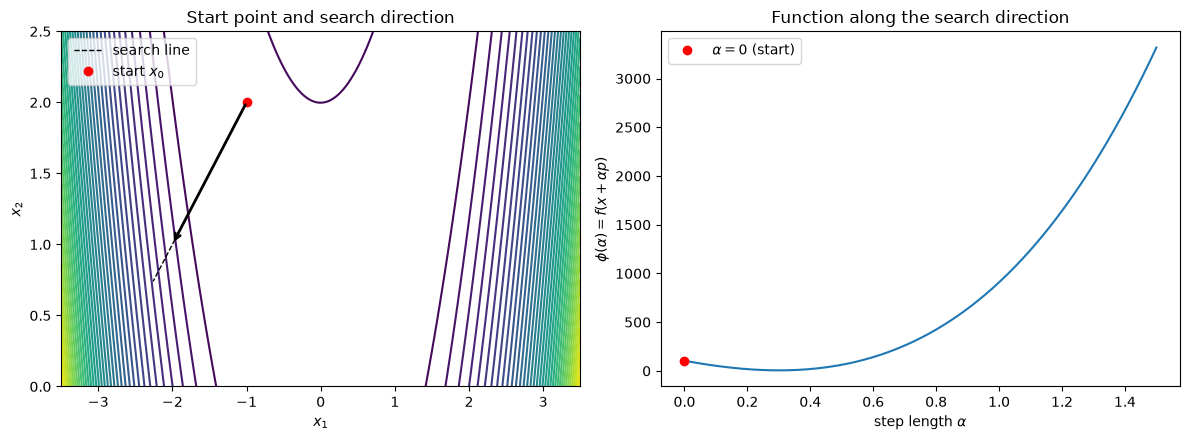

In [14]:
#  the rosenbrock function
x0 = np.array([-1, 2]) # starting point
p = np.array([-1, -1]) # search direction

alpha_init = 1.5
mu1, mu2, sigma = 1e-4, 0.9, 2.0

fig, (ax_contour, ax_line) = plt.subplots(1, 2, figsize=(12, 4.5))

# left: contours with start point, search direction (arrow) and search line
contour(rosenbrock, (-3.5, 3.5), (0, 2.5), ax=ax_contour)
end = x0 + alpha_max * p
ax_contour.plot(*zip(x0, end), "k--", lw=1, label="search line")
ax_contour.annotate("", xy=x0 + p, xytext=x0,
                    arrowprops=dict(arrowstyle="->", color="k", lw=2))
ax_contour.plot(*x0, "ro", label="start $x_0$")
ax_contour.set_title("Start point and search direction")
ax_contour.legend(loc="upper left")

# right: f along the search direction
lineplot(rosenbrock, x0, p, alpha_max=alpha_init, ax=ax_line)
ax_line.set_title("Function along the search direction")

plt.tight_layout()
plt.show()

## Results

## Interpretation